# PokéChallenge 2026 — who wins a Gen 2 OU battle?

Given the first 30 turns of a Pokémon Showdown Gen 2 OU battle, predict whether player 1 wins. This document rebuilds the **three submissions** of the challenge and reports their **experimental evaluation**.

| # | submission | what it is |
| --- | --- | --- |
| 1 | `compact_v5` | 18 hand-picked features, four boosters started from a logistic regression's log-odds (`ensemble_from_lr`, tuned members) |
| 2 | `v11` | 819 features, three stacked boosters and a spline logistic regression with a team effect, blended (`v11_blend`) |
| 3 | `blend` | the 50/50 average of the logits of the two |

Everything is fitted on `train.jsonl` only; the test battles are only predicted. The code is the repository at the tag `notebook-submission`, run in its own pinned environment (Python 3.14, versions in `requirements.txt`) through the repository's command line (`python main.py …`) and the scripts of `docs/evaluation/`.

## 1. Setup

Parameters of the original notebook:

- `REPOSITORY`: the project repository (pokechallenge-fall-2026)
- `REVISION = "notebook-submission"`: the tag of the submitted version (never moved)
- `RUN_EVALUATION = False`: use the stored tables of `docs/evaluation/data/` (about one hour); `True` reruns every experiment (several hours)
- `SEED = 33`: fold assignment of the evaluation (stratified grouped 5-fold)
- `TURNS = [1, 2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28]` (and 30, the whole battle)
- `CURVE_STEP = 250`: battles between two points of the learning curve

The results depend on the library versions (the exact v11 reproduction in particular), hence the dedicated environment.

In [1]:
REPOSITORY = "https://github.com/CiottoloMaggico/pokechallenge-fall-2026.git"
REVISION = "notebook-submission"  # the tag of the submitted version (never moved)
RUN_EVALUATION = False
SEED = 33  # the fold assignment of the evaluation (stratified grouped 5-fold)
TURNS = [1, 2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28]  # and 30, the whole battle
CURVE_STEP = 250  # battles between two points of the learning curve

In [2]:
import os
import sys
from pathlib import Path

ON_KAGGLE = Path("/kaggle/working").exists()
if ON_KAGGLE:
    CLONE = Path("/kaggle/temp/pokechallenge")  # not saved with the notebook
    if not CLONE.exists():
        !GIT_LFS_SKIP_SMUDGE=1 git clone --quiet --depth 1 --branch {REVISION} {REPOSITORY} {CLONE}
    os.chdir(CLONE)
    WORK, PYTHON = Path("/kaggle/working"), "/kaggle/temp/env/bin/python"
else:  # a local checkout: this file is docs/notebook/pokechallenge.ipynb
    if not Path("main.py").exists():
        os.chdir(Path.cwd().resolve().parents[1])
    WORK, PYTHON = Path("results/notebook"), ".env/bin/python"
WORK.mkdir(parents=True, exist_ok=True)
# every command below runs from the repository's root
!git log -1 --format="%h %s (%D)"

Note: switching to '018f0749e29b66afcc99448b52ddfa4cbd3ed7c3'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

018f074 docs(notebook): rebuild the notebook from the validated text, with its outputs (grafted, HEAD, tag: notebook-submission)


In [3]:
if not Path(PYTHON).exists():
    ENV = Path(PYTHON).parents[1]
    !{sys.executable} -m pip install --quiet uv
    !{sys.executable} -m uv venv --quiet --python 3.14 {ENV}
    !{sys.executable} -m uv pip install --quiet --python {PYTHON} -r requirements.txt
LIBRARIES = "'scikit-learn', 'lightgbm', 'xgboost', 'catboost'"
!{PYTHON} --version
!{PYTHON} -c "import importlib.metadata as m; print(*[p + ' ' + m.version(p) for p in ({LIBRARIES})])"

Python 3.14.10
scikit-learn 1.9.1 lightgbm 4.7.0 xgboost 3.4.1 catboost 1.2.10


## 2. Data, Pokédex and knockout detectors

Three things are built once from the **training file only**:

- the **Pokédex** (base stats and types of every species seen in the training records);
- the **knockout detector of `compact_v5`** (`v3`): the timeline does not show every faint of player 2's Pokémon, so a gradient boosting trained on player 1's switches (where the faint *is* recorded) estimates the hidden ones and repairs the replay before any feature is computed. It never sees `player_won`;
- the **knockout detector of `v11`**, the same idea with v11's own description of a switch.

Commands: `python -m domain build-pokedex`, `main.py detector train --version v3 --seeds 42 1 2`, `main.py detector train-v11 --version v1 --seeds 42 1 2`.

In [4]:
def data_file(name):
    """The competition file ``name``: under /kaggle/input, else the repository's input/."""
    found = sorted(Path("/kaggle/input").rglob(name)) if ON_KAGGLE else []
    path = found[0] if found else Path("input") / name
    if path.stat().st_size < 10_000:  # a Git LFS pointer, not the data
        raise FileNotFoundError(f"{path}: add the competition data to the notebook")
    return path


TRAIN, TEST = data_file("train.jsonl"), data_file("test.jsonl")
POKEDEX = "results/cache/species.json"
V3, V11 = "results/addons/knockouts/v3", "results/addons/knockouts_v11/v1"
REPAIR_V3, REPAIR_V11 = f"model={V3}", f"v11={V11}"
PARAMS = " ".join(str(path) for path in sorted(Path("assets/params").glob("compact_v5__*_lr.json")))
MAIN = f"{PYTHON} main.py --pokedex {POKEDEX}"  # the repository's command line

if not Path(POKEDEX).exists():
    !{PYTHON} -m domain build-pokedex {TRAIN} --out {POKEDEX}
if not Path(V3).exists():
    !{MAIN} detector train --train {TRAIN} --version v3 --seeds 42 1 2
if not Path(V11).exists():
    !{MAIN} detector train-v11 --train {TRAIN} --version v1 --seeds 42 1 2
assert all(Path(path).exists() for path in (POKEDEX, V3, V11)), "see the errors above"
print("train:", TRAIN, "| test:", TEST)

239 species written to results/cache/species.json (source sha256 78f9e91c51b92adebe803bb09221347a55423dce080e433465edf527d2c20d0d)
no stats in any record: cleffa (in 2 battle(s))
no stats in any record: horsea (in 1 battle(s))
no stats in any record: ledyba (in 2 battle(s))
no stats in any record: magikarp (in 1 battle(s))
no stats in any record: natu (in 3 battle(s))
no stats in any record: nidorina (in 1 battle(s))
no stats in any record: remoraid (in 2 battle(s))
no stats in any record: unown (in 4 battle(s))
  seed 42 done (29 s)
  seed 1 done (26 s)
  seed 2 done (26 s)
feature_set  model  n_seeds  accuracy_mean  accuracy_std  accuracy_seed_std  log_loss_mean  log_loss_std  log_loss_seed_std  roc_auc_mean  roc_auc_std  brier_mean  brier_std
ko_domain30 hgb_ko        3         0.9627        0.0022             0.0001         0.0992        0.0046             0.0004        0.9918       0.0008      0.0281     0.0015
  seed 42 done (18 s)
{
  "p2_repairs": 10109,
  "symmetry_estimate": 

## 3. The three submissions

Each model is fitted on the 10,000 training battles and predicts the 5,000 test battles.

- **`compact_v5`**: `ensemble_from_lr` with the hyper-parameters found by Optuna (`assets/params/`), on the replay repaired by detector `v3`.
- **`v11`**: the `blend_v11` model rebuilt on this repository's constructs (`v11_blend`), on the replay repaired by its own detector.
- **`blend`**: `expit(0.5 · logit(p_compact_v5) + 0.5 · logit(p_v11))`.

The experiments in section 4 were run locally, so the CSV files generated by the Kaggle notebook can differ slightly from the ones that were actually submitted. The models are the same and should perform about the same, within noise.

In [5]:
RUNS, SUBMISSIONS = WORK / "runs", WORK / "submissions"
MODELS = {  # name: (feature set, model, repair, extra options of train)
    "compact_v5": ("compact_v5", "ensemble_from_lr", REPAIR_V3, f"--params {PARAMS}"),
    "v11": ("v11", "v11_blend", REPAIR_V11, ""),
}
for name, (features, model, repair, extra) in MODELS.items():
    run = RUNS / (f"{features}__{model}" + ("-tuned" if extra else ""))
    if not run.exists():
        !{MAIN} train --train {TRAIN} --features {features} --models {model} --repair {repair} {extra} --out {RUNS}
    !{MAIN} predict --run {run} --test {TEST} --repair {repair} --out {SUBMISSIONS}/submission_{name}.csv --proba {SUBMISSIONS}/proba_{name}.csv
!{PYTHON} docs/evaluation/blend.py {SUBMISSIONS}/proba_compact_v5.csv {SUBMISSIONS}/proba_v11.csv --out {SUBMISSIONS}/submission_blend.csv --proba {SUBMISSIONS}/proba_blend.csv
for name in ("compact_v5", "v11", "blend"):
    assert (SUBMISSIONS / f"submission_{name}.csv").exists(), f"no {name} submission: see above"

saved /kaggle/working/runs/compact_v5__ensemble_from_lr-tuned
5000 predictions written to /kaggle/working/submissions/submission_compact_v5.csv (compact_v5__ensemble_from_lr-tuned)
probabilities written to /kaggle/working/submissions/proba_compact_v5.csv
saved /kaggle/working/runs/v11__v11_blend
5000 predictions written to /kaggle/working/submissions/submission_v11.csv (v11__v11_blend)
probabilities written to /kaggle/working/submissions/proba_v11.csv
5000 predictions written to /kaggle/working/submissions/submission_blend.csv


probabilities written to results/notebook/submissions/proba_compact_v5.csv


saved results/notebook/runs/v11__v11_blend


5000 predictions written to results/notebook/submissions/submission_v11.csv (v11__v11_blend)
probabilities written to results/notebook/submissions/proba_v11.csv


5000 predictions written to results/notebook/submissions/submission_blend.csv


## 4. Experimental evaluation

Every number below comes from cross-validation on the 10,000 training battles: 5 folds, stratified, with duplicated battles kept in the same fold, and one fold assignment (seed 33) shared by the three models. Everything that learns, features included, is refitted inside each training fold, and features that read the labels give their own training rows out of fold. The two knockout detectors are fitted once on the training file and never read the labels. The blend is computed from the out-of-fold probabilities of the two models.

To compare two models we look at their difference fold by fold and ask whether it is larger than the variation across folds. We use a single fold assignment and five folds, so these estimates are themselves noisy. The hyper-parameters of `compact_v5` were tuned on the same training battles (on a different fold assignment), so its numbers may be slightly optimistic; section 4.8 discusses this.

In [6]:
import pandas as pd

sys.path.insert(0, str(Path("docs/evaluation").resolve()))
import plots

plots.apple_style()
EVALUATION = WORK / "evaluation"
DATA = EVALUATION / "data" if RUN_EVALUATION else Path("docs/evaluation/data")
SUMMARIZE = f"{PYTHON} docs/evaluation/summarize.py"

if RUN_EVALUATION:
    for name, (features, model, repair, extra) in MODELS.items():
        !{MAIN} evaluate --train {TRAIN} --features {features} --models {model} --repair {repair} {extra} --seeds {SEED} --out {EVALUATION}/{name}
    !{SUMMARIZE} models --compact {EVALUATION}/compact_v5 --v11 {EVALUATION}/v11 --out {DATA}


def table(name):
    return pd.read_csv(DATA / f"{name}.csv")


FIGURES = WORK / "figures"
oof = table("oof")

### 4.1 Performance of the three models

Accuracy and ROC AUC: higher is better. Log loss: lower is better. "± fold" is the standard deviation of the accuracy over the five folds.

In [7]:
plots.metrics_table(table("metrics"))

Model,Accuracy,± fold,Log loss,ROC AUC
compact_v5,0.7184,0.0105,0.5407,0.7982
v11,0.7175,0.0047,0.5417,0.7979
blend 50/50,0.7232,0.0081,0.5355,0.8034


`compact_v5` and `v11` are practically equal on every metric: they differ by 0.0009 in accuracy and 0.001 in log loss, much less than the fold-to-fold spread of the accuracy (0.005 to 0.010). The blend is better than both: about 0.005 lower in log loss and 0.005 higher in ROC AUC, and this difference has the same sign in the paired fold-by-fold comparison. In accuracy the blend gains about half a point, which is smaller than the fold-to-fold spread, so for accuracy alone we cannot say that the gain is real.

### 4.2 ROC curves

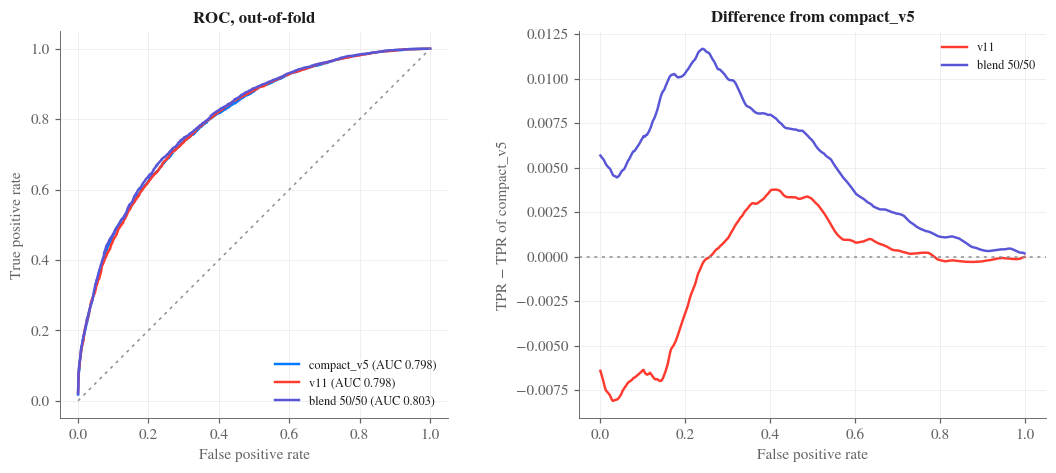

In [8]:
plots.plot_roc(oof, table("metrics"), FIGURES);

The left panel shows one ROC curve per model, built from its 10,000 out-of-fold probabilities. The three curves are almost on top of each other, and the AUC values (0.798, 0.798, 0.803) agree with the table. The right panel plots the difference in true positive rate with respect to `compact_v5` at each false positive rate, which makes the small differences visible. The blend is above `compact_v5` at every false positive rate, by about 0.01 around a false positive rate of 0.2 to 0.3. `v11` is below `compact_v5` at low false positive rates (about -0.007) and slightly above it between 0.3 and 0.6 (about +0.003). So the two single models rank the battles equally well overall but are not identical: each is slightly better in a different region. These curves come from a single run and have no confidence band, so we do not know how much of the wiggle in the difference panel is noise.

### 4.3 Accuracy by last turn seen

This plot asks how much of the outcome is already decided after N turns. Each training battle is cut to its first N turns, and the whole `compact_v5` pipeline (knockout repair, features, model) is cross-validated again on the cut battles with the same folds. The line is the mean accuracy over the folds and the band is one standard deviation.

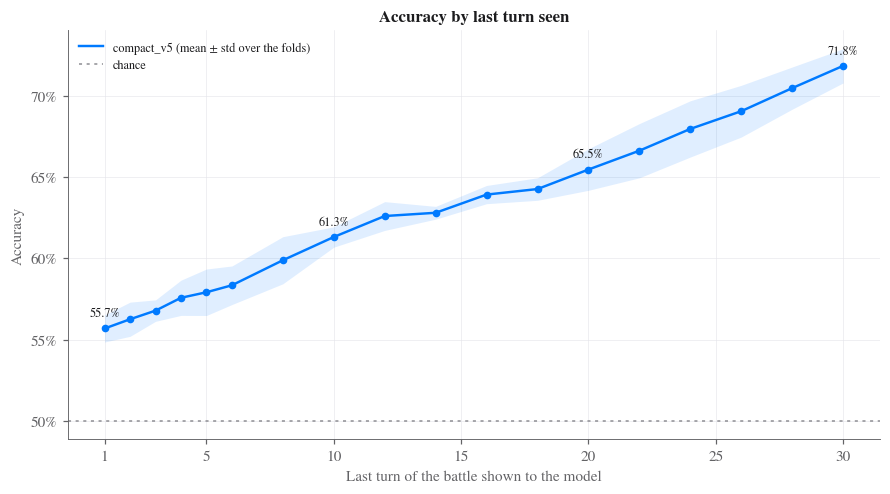

In [9]:
if RUN_EVALUATION:
    features, model, repair, extra = MODELS["compact_v5"]
    for turn in TURNS:
        cut = EVALUATION / "turns" / f"train_t{turn}.jsonl"
        !{PYTHON} docs/evaluation/truncate.py {TRAIN} --turn {turn} --out {cut}
        !{MAIN} evaluate --train {cut} --features {features} --models {model} --repair {repair} {extra} --seeds {SEED} --out {EVALUATION}/turns/t{turn}
        cut.unlink()
    !{SUMMARIZE} turns --runs {EVALUATION}/turns --full {EVALUATION}/compact_v5 --seed {SEED} --out {DATA}

plots.plot_accuracy_by_turn(table("accuracy_by_turn"), FIGURES);

Accuracy grows from 55.7% with only the first turn to 61.3% after 10 turns, 65.5% after 20 and 71.8% with all 30, so about half a point per turn on average. The growth is roughly linear and shows no sign of a plateau at turn 30. The band is about one point wide, so small steps between neighbouring turns (for example the flat stretch between turns 12 and 14) are not meaningful. Two things we can say: the models can already do better than chance with the first turn alone (we have not investigated which information produces the 55.7%, although the visible team of player 1 and the two leads are the obvious candidates), and the battle is still being decided when the recording ends, so 30 turns put a limit on what any model can reach. The experiment could not be run on v11, and therefore not on the blend, because of how the v11 feature set is defined: it is fixed at the last recorded turn and accepts no turn parameter, and its learned forecast group already works on truncated timelines, so its features cannot simply be recomputed on battles cut at turn N. We ran this experiment only for `compact_v5`, so we cannot say whether `v11` or the blend behave differently.

### 4.4 Accuracy vs confidence

Here the confidence of a prediction is the probability the model gives to the class it predicts, max(p, 1 - p), where p is the predicted probability that player 1 wins. For each threshold t on the x axis, the top panel shows the accuracy on the battles whose confidence is at least t, and the bottom panel shows the share of battles that are left (coverage).

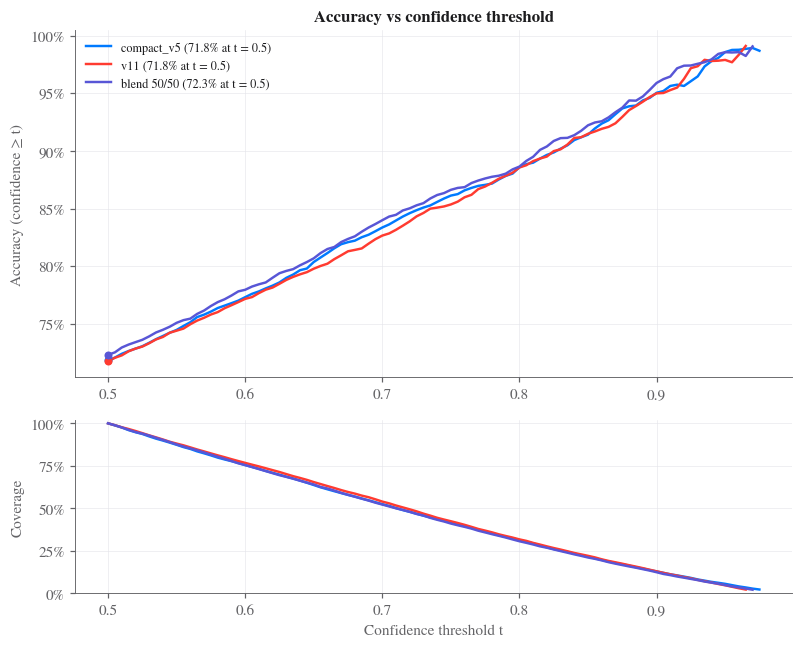

In [10]:
confidence = plots.confidence_table(oof, DATA)
plots.plot_accuracy_vs_confidence(confidence, FIGURES);

Accuracy increases steadily with confidence: about 83% when keeping the battles with confidence of at least 0.7 (roughly half of them) and about 95% at 0.9 (about 13% of them). The coverage falls almost linearly, which means that the confidences are spread fairly evenly between 0.5 and 1 rather than concentrated near 0.5. The accuracy of the selected battles is close to their average confidence, which is what we expect from calibrated probabilities (see 4.5). The three models are close: the blend is about half a point to one point above the others for thresholds between 0.55 and 0.8, and `v11` is slightly below `compact_v5` in the same range. Beyond about 0.93 only a few hundred battles remain and the lines become noisy.

### 4.5 Calibration

Calibration asks whether a probability can be taken at face value: among the battles to which a model gives about 70% for player 1, does player 1 win about 70% of them? We group the out-of-fold predictions in ten bins of p. The x axis is the mean predicted probability in a bin and the y axis is the observed share of player-1 wins in it, so a perfectly calibrated model lies on the diagonal. The bars below show how many battles fall in each bin. The ECE in the legend is the average distance from the diagonal, weighted by bin size.

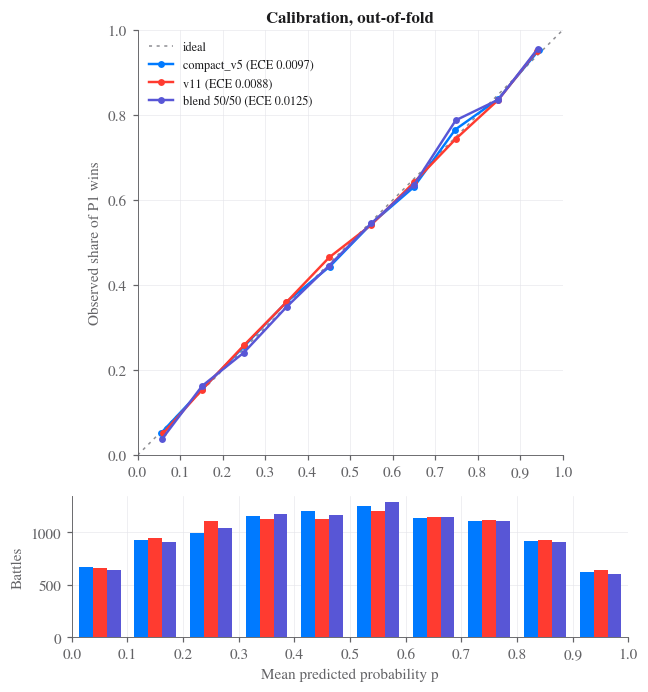

In [11]:
calibration = plots.calibration_table(oof, DATA)
plots.plot_calibration(calibration, FIGURES);

All three models are close to the diagonal (ECE 0.0097 for `compact_v5`, 0.0088 for `v11`, 0.0125 for the blend), and we see no systematic over- or under-confidence. The blend has the highest ECE, mostly because of the bin around 0.75, where it observes about 0.79. With about 1,100 battles in a bin the binomial noise is around 1.3 points, so that deviation is larger than noise alone would suggest, but it is a single bin and we did not investigate it. The ECE differences between models (0.001 to 0.004) are small. The consequence is that the better log loss of the blend is not explained by better calibration; it is more likely related to better ranking of the battles (the higher AUC), although we have not tested this. The bars also show that all models spread their predictions over the whole range instead of staying around 0.5.

### 4.6 Agreement between `compact_v5` and `v11`

We split the 10,000 battles into those on which `compact_v5` and `v11` predict the same winner (agreement) and those on which they predict different winners (disagreement). The x axis shows the two groups with their sizes, the y axis is the accuracy on the group, and each group has one bar per model with an interval computed over battles.

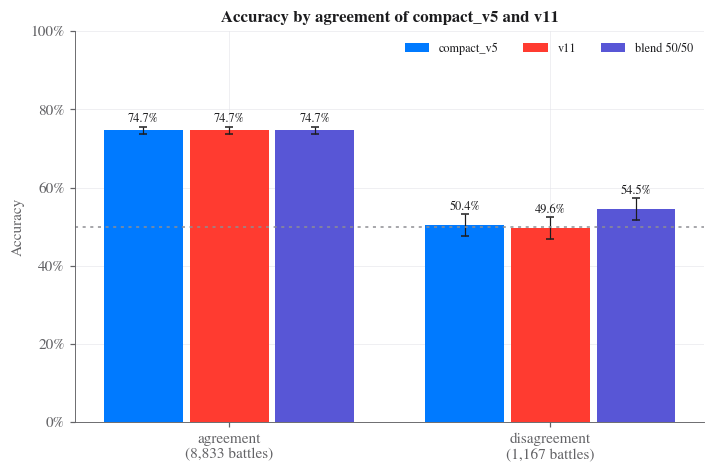

In [12]:
disagreement = plots.disagreement_table(oof, DATA)
plots.plot_disagreement(disagreement, FIGURES);

The two models agree on 8,833 battles (88.3%) and are right on 74.7% of them. The blend gives the same prediction as them there, so the three bars are equal. They disagree on 1,167 battles (11.7%). There `compact_v5` is right 50.4% of the time and `v11` 49.6%: when they disagree exactly one is right, so the two numbers add up to 100%, and neither is better than a coin flip on these battles. The blend reaches 54.5%, with an interval of about 52% to 57%. All the accuracy that the blend gains over the single models comes from this group: about 4 points on 11.7% of the battles is about half a point overall, which matches 72.3% against 71.8% in the table.

This suggests that, when the models disagree, the one that is more confident is slightly more often right, and the blend exploits it. We should be careful: the lower end of the interval is close to 50%, so the effect is not strongly established. We also did not check the confidence of the models on these battles, but it is likely that they are mostly hard, borderline battles. Reading the plot the other way round, the disagreement is mostly noise on difficult battles and only partly a sign that the two models know complementary things.

### 4.7 Validation log loss by training size

This plot asks how much the models improve with more training data. For one validation fold (2,000 battles) each model is refitted from scratch, features included, on the first n of the other 8,000 battles (in a fixed random order, with a point every 250 battles). The x axis is n and the y axis is the log loss on the validation fold. The subsets are nested, so a curve changes only because battles are added.

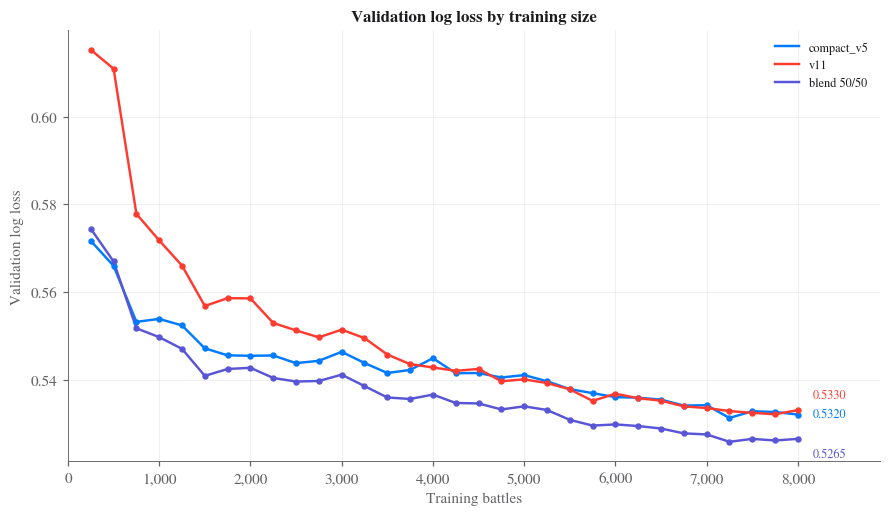

In [13]:
if RUN_EVALUATION:
    sizes = " ".join(str(size) for size in range(CURVE_STEP, 8000, CURVE_STEP))
    for name, (features, model, repair, extra) in MODELS.items():
        !{PYTHON} docs/evaluation/learning_curve.py --train {TRAIN} --pokedex {POKEDEX} --features {features} --models {model} --repair {repair} {extra} --seed {SEED} --folds 0 --sizes {sizes} --out {EVALUATION}/curve_{name}.csv
    !{SUMMARIZE} curve --compact {EVALUATION}/curve_compact_v5.csv --v11 {EVALUATION}/curve_v11.csv --out {DATA}

plots.plot_loss_convergence(table("loss_curve"), FIGURES);

All curves decrease quickly during the first 1,500 battles and more slowly afterwards, and they are still decreasing at 8,000 (final values 0.5320 for `compact_v5`, 0.5330 for `v11`, 0.5265 for the blend). Since the curves have not flattened, more data would probably still help a little, but we cannot extrapolate how much. The final models use 10,000 battles, so they sit slightly further to the right than the last point of this plot. `v11` starts much worse than `compact_v5` (0.615 against 0.572 with 250 battles) and reaches it at about 4,000 to 5,000 battles, which fits the idea that a model with 819 features needs more data than one with 18. The blend is the lowest curve from about 750 battles on. These curves come from a single validation fold, so differences of a few thousandths are within noise.

### 4.8 Training vs validation log loss and the generalisation gap

In the same experiment we also measure the log loss on the training battles themselves (dashed line), for each of the three models. The generalisation gap is the distance between the validation line and the training line: it tells us how much better a model looks on battles it was fitted on than on battles it has never seen. A large gap means that the model has partly memorised noise that is specific to its training battles. With few training battles it is easy to memorise them, so the gap is large at the start and shrinks as battles are added. Note that the training loss of the boosters is computed on data they were fitted on, so it is an optimistic measure by construction and should be read only through the gap, not as a real performance.

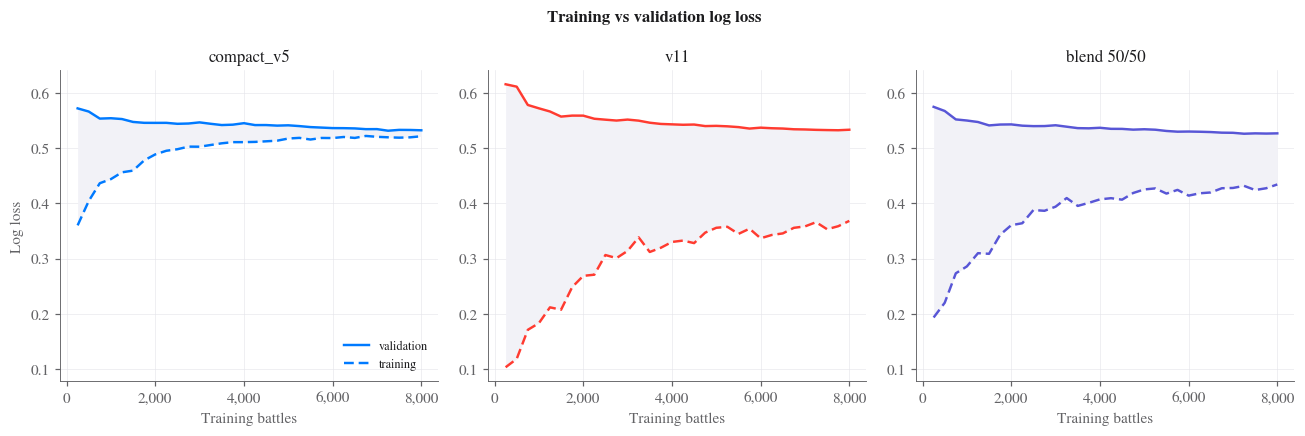

In [14]:
plots.plot_generalization_gap(table("loss_curve"), FIGURES);

The two models behave very differently here even though they end with the same validation loss. At 8,000 battles the gap of `compact_v5` is about 0.011 (training about 0.521, validation 0.532), while the gap of `v11` is about 0.165 (training about 0.37, validation 0.533) and shrinks only slowly. The blend lies in between (about 0.09). So `v11` reaches the same validation loss while fitting its training battles much better, which is what we expect from a model with many more columns and flexible boosters. For the same performance, the simpler model has less room to overfit and is easier to trust.

There is a caveat that works in the opposite direction: the small gap of `compact_v5` is probably a little too optimistic. Its 18 features were chosen from a pool of 37 candidates with a forward and backward selection that kept a column when the cross-validated loss improved, and its hyper-parameters were tuned on the same 10,000 battles. Selection that looks at the evaluation folds tends to keep features that look good partly by chance on those specific battles, so the validation loss of `compact_v5` is not completely "unseen" data for the procedure that produced the model. The hyper-parameters were tuned on a different fold assignment, which reduces but does not remove the problem, because the battles are the same. We have not measured how large this effect is; doing so would need repeating the selection inside each training fold (nested cross-validation). `v11` was also built while looking at the training data, but without an automatic selection loop of this kind, so we expect it to be affected less, without being able to prove it.

The private test goes in the same direction, but we cannot conclude much from it. The two submissions scored 70.08% (`compact_v5`) and 70.54% (`v11`), both below the cross-validated 71.8%. In our local run they disagree on about 560 of the 5,000 test battles, which gives a standard error of roughly 0.5 points for the difference between their accuracies, so a difference of 0.46 points is about one standard error. It is compatible with equal performance, with a small advantage of `v11`, and also with the optimism of `compact_v5` described above.

## 5. Conclusions

- `compact_v5` (18 features) and `v11` (819 features) have the same accuracy, log loss and ROC AUC within the noise of our cross-validation.
- Their 50/50 blend has a lower log loss and a higher ROC AUC. The accuracy gain is about half a point and cannot be separated from noise. All of it comes from the 11.7% of battles on which the two models disagree.
- All three models are well calibrated, so their probabilities can be used as they are.
- The outcome becomes predictable gradually, about half a point of accuracy per turn, from 55.7% after the first turn to 71.8% with all 30. The battles are not yet decided when the recording stops.
- The validation loss is still decreasing at 8,000 battles, so more data would probably help slightly. The large model needs more data to catch up with the small one and fits its training battles far better (gap 0.165 against 0.011).
- The comparison between the two models is probably slightly favourable to `compact_v5`, because its features and hyper-parameters were selected on the same battles. We have not measured how much.